# Multimodal AI Experiment

## 1. Objective

To understand the fundamentals of Multimodal AI, how AI models process and combine different types of inputs such as text, images, audio, and video, and how multimodal models can generate meaningful responses from these inputs.

## 2. Practical Experiment

### Objective

To test how a Multimodal AI model processes an image together with a text prompt and generates a meaningful response.

In this experiment, we will provide:

- An image as the visual input
- A text prompt as the instruction
- A multimodal AI model to process both inputs
- A text response generated based on the image and prompt

### Experiment Flow

Image + Text Prompt
↓
Multimodal AI Model
↓
Image and Text Understanding
↓
Generated Text Response

### Installing Pillow

Pillow is a Python library used to work with images. It allows us to open, resize, and display images in our Multimodal AI experiment.

- `import sys` identifies the Python environment used by the current Jupyter Notebook.
- `!{sys.executable} -m pip install pillow` installs Pillow in that same Python environment.

**Why is it needed?** We use Pillow to load and prepare images before sending them to the AI model.

In [4]:
import sys
!{sys.executable} -m pip install pillow

   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.2 MB ? eta -:--:--
   ---------- ----------------------------- 1.8/7.2 MB 5.7 MB/s eta 0:00:01
   --------------- ------------------------ 2.9/7.2 MB 5.5 MB/s eta 0:00:01
   ----------------------- ---------------- 4.2/7.2 MB 5.8 MB/s eta 0:00:01
   ------------------------------- -------- 5.8/7.2 MB 6.0 MB/s eta 0:00:01
   --------------------------------- ------ 6.0/7.2 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------  7.1/7.2 MB 5.4 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 5.0 MB/s  0:00:01


### Importing Required Libraries

These libraries help us work with images and communicate with the AI model through an API.

- **`requests`** – Sends requests to the AI model and receives its responses.
- **`base64`** – Converts image data into a format that can be sent through an API.
- **`time`** – Measures how long the AI model takes to respond.
- **`PIL.Image`** – Opens and handles images using the Pillow library.
- **`display`** – Displays images directly in the Jupyter Notebook.

**Purpose:** These libraries are required to send image inputs to the AI model, receive responses, and display images during our Multimodal AI experiment.

In [4]:
import requests
import base64
import time
from PIL import Image
from IPython.display import display

print("All libraries imported successfully! ✅")

All libraries imported successfully! ✅


In [5]:
from dotenv import load_dotenv
import os

load_dotenv()

api_key = os.getenv("OPENROUTER_API_KEY")

print("API key loaded successfully! ✅" if api_key else "API key not found! ❌")

API key loaded successfully! ✅


In [25]:
MODEL = "dots-studio/dots-3-note-preview:free"
API_URL = "https://openrouter.ai/api/v1/chat/completions"
results = []

def image_to_data_url(path):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode("utf-8")
    ext = path.rsplit(".", 1)[-1].lower().replace("jpg", "jpeg")
    return f"data:image/{ext};base64,{b64}"

def ask(name, prompt, image_path=None):
    parts = [{"type": "text", "text": prompt}]
    if image_path:
        parts.append({"type": "image_url", "image_url": {"url": image_to_data_url(image_path)}})
    payload = {"model": MODEL, "messages": [{"role": "user", "content": parts}], "max_tokens": 1500}
    headers = {"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"}
    start = time.time()
    for attempt in range(6):
        r = requests.post(API_URL, headers=headers, json=payload, timeout=180)
        try:
            data = r.json()
        except Exception:
            data = {}
        err_code = data.get("error", {}).get("code") if isinstance(data.get("error"), dict) else None
        temporary = r.status_code in (429, 502, 503) or err_code in (429, 502, 503)
        if not temporary:
            break
        print(f"Provider busy ({err_code or r.status_code}), retry {attempt+1}/6 in 20 seconds...")
        time.sleep(20)
    latency = round(time.time() - start, 2)
    if "choices" in data:
        msg = data["choices"][0]["message"]
        answer = msg.get("content") or msg.get("reasoning") or "(empty response)"
        usage, status = data.get("usage", {}), "OK"
    else:
        answer = f"ERROR {r.status_code}: {r.text[:500]}"
        usage, status = {}, "FAILED"
    results.append({"experiment": name, "model": MODEL, "status": status, "latency_sec": latency,
                    "prompt_tokens": usage.get("prompt_tokens"),
                    "completion_tokens": usage.get("completion_tokens"), "answer": answer})
    print(f"[{name}] {status} | {latency}s | tokens: {usage.get('prompt_tokens')}/{usage.get('completion_tokens')}\n")
    print(answer)

print("Helper ready")

Helper ready


### Experiment 1: Image Description Using Text and Image Input

This experiment tests whether the AI model can understand an image and describe its contents using a text prompt.

- **`Image.open("laptop.png")`** – Opens the laptop image using Pillow.
- **`.resize((350, 250))`** – Resizes the displayed image to 350 pixels wide and 250 pixels high.
- **`display()`** – Displays the resized image in the Jupyter Notebook.
- **`ask()`** – Sends the text prompt and the original image to the AI model.
- **`"1B Image + text"`** – Gives the experiment a name for tracking its result.
- **`"Describe this image in 3 short bullet points."`** – Instructs the AI model to describe the image in three short bullet points.
- **`"laptop.png"`** – Specifies the image file sent to the AI model.

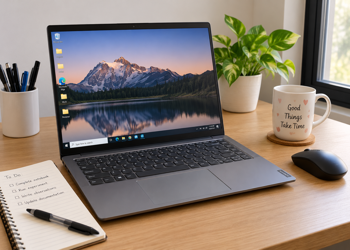

[1B Image + text] OK | 25.57s | tokens: 1301/507



* **Central Focus:** A sleek grey laptop is open on a light wooden desk, displaying a scenic wallpaper of a snow-capped mountain reflecting in a calm lake.
* **Productive Accessories:** To the left, a spiral notebook displays a handwritten "To Do" list with a black pen resting on it, while a white cup holding pens stands nearby, alongside a black mouse on the right.
* **Cozy Workspace Details:** A white mug with the encouraging text "Good Things Take Time" sits on a cork coaster next to a vibrant green potted plant, adding a warm, organized, and natural touch to the productive setup.


In [28]:
display(Image.open("laptop.png").resize((350, 250)))
ask("1B Image + text", "Describe this image in 3 short bullet points.", "laptop.png")

 # Invoice Information Extraction from the image

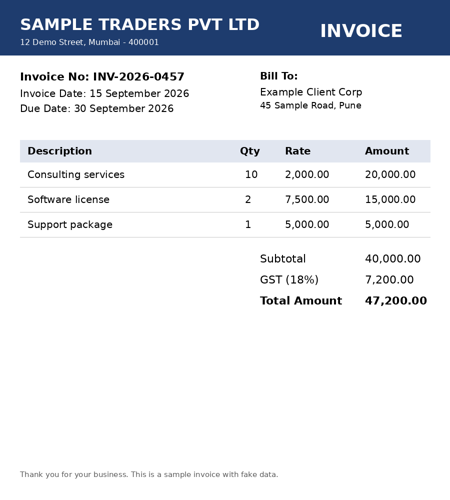

[2 Invoice extraction] OK | 11.01s | tokens: 1186/454



```json
{
  "invoice_number": "INV-2026-0457",
  "invoice_date": "15 September 2026",
  "total_amount": "47,200.00"
}
```


In [29]:
display(Image.open("invoice.png").resize((450, 500)))
ask("2 Invoice extraction",
    "Extract the invoice number, invoice date and total amount from this image. Reply only in JSON.",
    "invoice.png")

### Generating a Sample Audio File

This code converts a text sentence into spoken audio and saves it as a WAV file using Windows PowerShell.

- **`import subprocess, os`** – `subprocess` runs PowerShell commands from Python, while `os` handles file paths and file information.
- **`text`** – Stores the sentence that will be converted into speech.
- **`os.path.abspath("clip.wav")`** – Gets the full path where the audio file will be saved.
- **`ps`** – Stores the PowerShell commands used to generate the audio.
- **`System.Speech`** – Provides Windows text-to-speech functionality.
- **`SpeechSynthesizer`** – Converts the written sentence into spoken audio.
- **`SetOutputToWaveFile()`** – Specifies the WAV file where the generated speech will be saved.
- **`Speak(text)`** – Reads the sentence aloud and generates the audio.
- **`Dispose()`** – Releases the speech synthesizer resources after use.
- **`subprocess.run()`** – Executes the PowerShell commands from Python.
- **`os.path.getsize()`** – Gets the audio file size in bytes, which is converted into kilobytes for display.

**Expected result:** A file named `clip.wav` is created, containing the spoken sentence, and its file path and approximate size are displayed.

**Note:** This code uses Windows PowerShell and the Windows speech synthesis feature, so it requires a compatible Windows environment.


In [51]:
import subprocess, os

text = "Hello team. This is a sample audio test. The billing review meeting is on Friday at 3 PM in conference room 2. Please bring the monthly report."
wav_path = os.path.abspath("clip.wav")

ps = (
    "Add-Type -AssemblyName System.Speech; "
    "$s = New-Object System.Speech.Synthesis.SpeechSynthesizer; "
    f"$s.SetOutputToWaveFile('{wav_path}'); "
    f"$s.Speak('{text}'); "
    "$s.Dispose()"
)
subprocess.run(["powershell", "-NoProfile", "-Command", ps])
print("Created:", wav_path, "| size KB:", round(os.path.getsize(wav_path) / 1024))

Created: C:\Users\vishakha.more\AI Assignment\clip.wav | size KB: 504


### Playing the Generated Audio

This code plays the audio file created in the previous step directly inside the Jupyter Notebook.

- **`from IPython.display import Audio`** – Imports the `Audio` tool, which allows audio playback inside the notebook.
- **`Audio("clip.wav")`** – Loads the `clip.wav` file and displays an audio player so we can listen to the generated speech.


In [52]:
from IPython.display import Audio
Audio("clip.wav")

### Preparing Audio and Video Inputs

- **`file_to_b64(path)`** – Reads an audio or video file and converts its binary data into Base64-encoded text.
- **`ask_media(name, prompt, media_path, kind, model)`** – Defines a reusable function to send an audio or video file along with a text prompt to an AI model.
- **`if kind == "audio"`** – Checks whether the input is an audio file.
- **`media_path.rsplit(".", 1)[-1].lower()`** – Extracts the file extension, such as `wav` or `mp3`.
- **`part`** – Stores the audio or video data in the format expected by the API request.
- **`payload`** – Combines the selected model, text prompt, and media input into a request.
- **`headers`** – Adds the API key and specifies that the request contains JSON.
- **`start = time.time()`** – Records the start time to measure the response duration.
- **`for attempt in range(4)`** – Allows up to four attempts to send the request.
- **`requests.post()`** – Sends the request to the OpenRouter API.
- **`r.json()`** – Attempts to convert the API response into a Python dictionary.
- **`err`** – Retrieves the error code when the API returns an error object.
- **`time.sleep(20)`** – Waits 20 seconds before retrying if the provider is temporarily busy.
- **`latency`** – Calculates the total time taken by the request.
- **`if "choices" in data`** – Checks whether the response contains a model output.
- **`answer`** – Stores the generated response or an error message.
- **`usage` and `status`** – Store token usage information and whether the request succeeded or failed.
- **`results.append()`** – Saves the experiment details and response in the results list.
- **`print()`** – Displays the experiment name, model, status, response time, token usage, and answer.
- **`print("Media helper ready")`** – Confirms that the helper functions have been defined.

**Note:** The final print statement confirms that the functions are defined; it does not confirm that the API request will succeed. The selected model must support the media format being sent.

In [53]:
def file_to_b64(path):
    with open(path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

def ask_media(name, prompt, media_path, kind, model):
    if kind == "audio":
        fmt = media_path.rsplit(".", 1)[-1].lower()
        part = {"type": "input_audio", "input_audio": {"data": file_to_b64(media_path), "format": fmt}}
    else:
        part = {"type": "video_url", "video_url": {"url": "data:video/mp4;base64," + file_to_b64(media_path)}}
    payload = {"model": model, "messages": [{"role": "user", "content": [{"type": "text", "text": prompt}, part]}], "max_tokens": 1500}
    headers = {"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"}
    start = time.time()
    for attempt in range(4):
        r = requests.post(API_URL, headers=headers, json=payload, timeout=300)
        try:
            data = r.json()
        except Exception:
            data = {}
        err = data.get("error", {}).get("code") if isinstance(data.get("error"), dict) else None
        if not (r.status_code in (429, 502, 503) or err in (429, 502, 503)):
            break
        print(f"Provider busy, retry {attempt+1}/4 in 20 seconds...")
        time.sleep(20)
    latency = round(time.time() - start, 2)
    if "choices" in data:
        msg = data["choices"][0]["message"]
        answer = msg.get("content") or msg.get("reasoning") or "(empty response)"
        usage, status = data.get("usage", {}), "OK"
    else:
        answer, usage, status = f"ERROR {r.status_code}: {r.text[:500]}", {}, "FAILED"
    results.append({"experiment": name, "model": model, "status": status, "latency_sec": latency,
                    "prompt_tokens": usage.get("prompt_tokens"),
                    "completion_tokens": usage.get("completion_tokens"), "answer": answer})
    print(f"[{name}] {status} | {model} | {latency}s | tokens: {usage.get('prompt_tokens')}/{usage.get('completion_tokens')}\n")
    print(answer)

print("Media helper ready")

Media helper ready


### Installation Command
Installs Whisper so we can convert audio files into text locally.

`%pip install -U openai-whisper`

- `%pip` — Installs packages in the current Jupyter environment.
- `install` — Installs the package.
- `-U` — Upgrades to the latest available version.
- `openai-whisper` — Library used for speech-to-text transcription.


In [59]:
%pip install -U openai-whisper

Note: you may need to restart the kernel to use updated packages.


### Purpose of `imageio-ffmpeg`

`imageio-ffmpeg` provides an FFmpeg executable that can be used to process audio and video files.

- **Why it is used:** FFmpeg is required by Whisper to read and process audio files.
- **`get_ffmpeg_exe()`** retrieves the location of the FFmpeg executable.

**Purpose:** Helps Whisper access FFmpeg for local audio transcription, even when FFmpeg is not installed separately on the system.

In [61]:
%pip install imageio-ffmpeg

   ---------------------------------------- 0.0/31.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.2 MB ? eta -:--:--
    --------------------------------------- 0.5/31.2 MB 996.1 kB/s eta 0:00:31
   - -------------------------------------- 0.8/31.2 MB 1.1 MB/s eta 0:00:27
   - -------------------------------------- 1.0/31.2 MB 1.2 MB/s eta 0:00:26
   - -------------------------------------- 1.3/31.2 MB 1.1 MB/s eta 0:00:27
   - -------------------------------------- 1.3/31.2 MB 1.1 MB/s eta 0:00:27
   -- ------------------------------------- 1.6/31.2 MB 1.1 MB/s eta 0:00:27
   -- ------------------------------------- 1.8/31.2 MB 1.1 MB/s eta 0:00:28
   -- ------------------------------------- 2.1/31.2 MB 1.1 MB/s eta 0:00:27
   --- ------------------------------------ 2.4/31.2 MB 1.1 MB/s eta 0:00:26
   --- ------------------------------------ 2.6/31.2 MB 1.1 MB/s eta 0:00:26
   --- ------------------------------------ 2.9/31.2 MB 1.1 MB/s eta 0:00:25
   ---- ---

### Configure FFmpeg for Whisper

This cell configures FFmpeg so that Whisper can find and use it for audio processing.

- **`imageio_ffmpeg.get_ffmpeg_exe()`** – Gets the path of the FFmpeg executable.
- **`tempfile.mkdtemp()`** – Creates a temporary directory.
- **`shutil.copy2()`** – Copies the FFmpeg executable into that directory with the name `ffmpeg.exe`.
- **`os.environ["PATH"]`** – Adds the directory to PATH so Whisper can find FFmpeg.
- **`shutil.which("ffmpeg")`** – Checks whether FFmpeg can be located by its command name.
- **`subprocess.run()`** – Executes `ffmpeg -version` to verify that FFmpeg works.
- **`torch.__version__`** – Displays the installed PyTorch version.

**Purpose:** Fixes FFmpeg command discovery on Windows and verifies that FFmpeg and the required Python libraries are ready for local audio transcription.

In [3]:
import os
import shutil
import tempfile
import subprocess
import imageio_ffmpeg
import whisper
import torch

# Locate FFmpeg
ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()

# Create a directory with the filename Whisper expects
ffmpeg_dir = tempfile.mkdtemp(prefix="whisper_ffmpeg_")
ffmpeg_named = os.path.join(ffmpeg_dir, "ffmpeg.exe")
shutil.copy2(ffmpeg_exe, ffmpeg_named)

# Add FFmpeg to PATH
os.environ["PATH"] = ffmpeg_dir + os.pathsep + os.environ["PATH"]

# Verify setup
print("Whisper imported successfully")
print("PyTorch version:", torch.__version__)
print("FFmpeg command:", shutil.which("ffmpeg"))
print("FFmpeg test:", subprocess.run(
    ["ffmpeg", "-version"], capture_output=True
).returncode == 0)

Whisper imported successfully
PyTorch version: 2.14.1+cpu
FFmpeg command: C:\Users\VISHAK~1.MOR\AppData\Local\Temp\whisper_ffmpeg_ptjrtk_h\ffmpeg.EXE
FFmpeg test: True


### Local Audio Transcription Using Whisper

This cell checks whether the audio file exists, loads the Whisper model, and converts the audio into text.

- **`os.path.exists("clip.wav")`** – Checks whether the audio file exists.
- **`whisper.load_model("tiny")`** – Loads the lightweight Whisper model for transcription.
- **`model.transcribe("clip.wav", fp16=False)`** – Transcribes the audio file into text. `fp16=False` disables half-precision processing.
- **`result["text"]`** – Extracts the transcribed text from the result.

**Purpose:** Demonstrates local speech-to-text transcription using Whisper without requiring an external transcription API.

In [69]:
import os
import whisper

print("Audio file exists:", os.path.exists("clip.wav"))

model = whisper.load_model("tiny")

result = model.transcribe("clip.wav", fp16=False)

print("Transcription:")
print(result["text"])

Audio file exists: True
Transcription:
 Hello Team. This is a sample audio test. The billing review meeting is on Friday at 3pm in conference room 2. Please bring the monthly report.


### Experiment 3: Video Input — Check Video File

This cell verifies that the input video file is available before processing it with a multimodal AI model.

- **`video_path = "horse.mp4"`** – Specifies the path of the input video.
- **`os.path.exists(video_path)`** – Checks whether the video file exists.
- **`os.path.getsize(video_path)`** – Retrieves the video file size in bytes.
- **`/ 1024`** – Converts the file size into kilobytes (KB).
- **`round(..., 2)`** – Rounds the file size to two decimal places.

**Purpose:** Confirms that the video is available and ready for the next processing step.

**Note:** This cell only checks the video file. It does not analyze the video's content or use an AI model yet.

In [72]:
import os

video_path = "horse.mp4"

print("Video exists:", os.path.exists(video_path))
print("Video size:", round(os.path.getsize(video_path) / 1024, 2), "KB")

Video exists: True
Video size: 3705.69 KB


In [73]:
%pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 228.7 kB/s eta 0:03:11
    --------------------------------------- 0.8/44.0 MB 391.6 kB/s eta 0:01:51
    --------------------------------------- 1.0/44.0 MB 518.5 kB/s eta 0:01:23
   - -------------------------------------- 1.6/44.0 MB 732.0 kB/s eta 0:00:58
   - -------------------------------------- 1.8/44.0 M

### Explore Models Supporting Image Input

This cell filters the available OpenRouter models to identify those that support image input.

- **`for m in models`** – Iterates through the available models.
- **`m.get("architecture", {}).get("modality", "")`** – Retrieves each model's supported input and output modalities.
- **`if "image" in modality.lower()`** – Filters models whose modality information includes image support.
- **`print()`** – Displays the model ID and its modality information.

**Purpose:** Helps identify models that can process images, which is useful when selecting a vision-capable model for video frame analysis.

**Note:** This list depends on the models returned by the API. Image support does not automatically mean direct video support.

In [81]:
for m in models:
    modality = m.get("architecture", {}).get("modality", "")

    if "image" in modality.lower():
        print("Model:", m.get("id"))
        print("Modality:", modality)
        print("-" * 50)

Model: anthropic/claude-haiku-5.5
Modality: text+image+file->text
--------------------------------------------------
Model: anthropic/claude-haiku-5.5:batch
Modality: text+image+file->text
--------------------------------------------------
Model: google/gemini-nano-banana-2.1
Modality: text+image->text+image
--------------------------------------------------
Model: mistralai/mistral-large-4-0
Modality: text+image->text
--------------------------------------------------
Model: unbiased/pareto-26.10-preview
Modality: text+image->text
--------------------------------------------------
Model: openai/gpt-6.1-sol-pro
Modality: text+image+file->text
--------------------------------------------------
Model: openai/gpt-6.1-sol
Modality: text+image+file->text
--------------------------------------------------
Model: anthropic/claude-sonnet-5.5
Modality: text+image+file->text
--------------------------------------------------
Model: anthropic/claude-sonnet-5.5:batch
Modality: text+image+file->tex

### Extract and Save Video Frames Using OpenCV

This cell extracts three frames from the input video `horse.mp4` and saves them as image files for AI analysis.

- **`cv2.VideoCapture(video_path)`** – Opens the video file.
- **`cv2.CAP_PROP_FRAME_COUNT`** – Retrieves the total number of frames in the video.
- **`frame_paths = []`** – Creates a list to store the paths of the extracted frames.
- **`[0.25, 0.50, 0.75]`** – Specifies the positions at which frames are extracted: 25%, 50%, and 75% of the video.
- **`cap.set()`** – Moves to the selected frame position.
- **`cap.read()`** – Reads the selected video frame.
- **`cv2.imwrite()`** – Saves each extracted frame as a JPEG image.
- **`frame_paths.append(path)`** – Stores the image path for use in the next step.
- **`cap.release()`** – Releases the video resource after processing.

**Purpose:** Converts selected parts of the video into image files that can be provided to a vision-capable AI model for visual analysis and video explanation.

In [82]:

import cv2
from IPython.display import display, Image

video_path = "horse.mp4"

cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Total frames:", total_frames)

frame_paths = []

for i, position in enumerate([0.25, 0.50, 0.75], start=1):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(total_frames * position))
    success, frame = cap.read()

    if success:
        path = f"horse_frame_{i}.jpg"
        cv2.imwrite(path, frame)
        frame_paths.append(path)
        print(f"Saved: {path}")

cap.release()


Total frames: 360
Saved: horse_frame_1.jpg
Saved: horse_frame_2.jpg
Saved: horse_frame_3.jpg


### Create a Video Frame Contact Sheet

This cell combines the three frames extracted from `horse.mp4` into a single image for easy visual comparison.

- **`PILImage.open()`** – Opens the extracted frame images.
- **`convert("RGB")`** – Converts each image to RGB format.
- **`target_width = 480`** – Sets a consistent width for all frames.
- **`frame.resize()`** – Resizes each frame while maintaining its aspect ratio.
- **`PILImage.new()`** – Creates a blank canvas to arrange the frames horizontally.
- **`canvas.paste()`** – Places each resized frame next to the previous one.
- **`canvas.save()`** – Saves the combined image as `horse_contact_sheet.jpg`.
- **`display(canvas)`** – Displays the contact sheet in the notebook.

**Purpose:** Makes it easier to compare the horse's appearance, position, and visible changes across the three selected video frames.

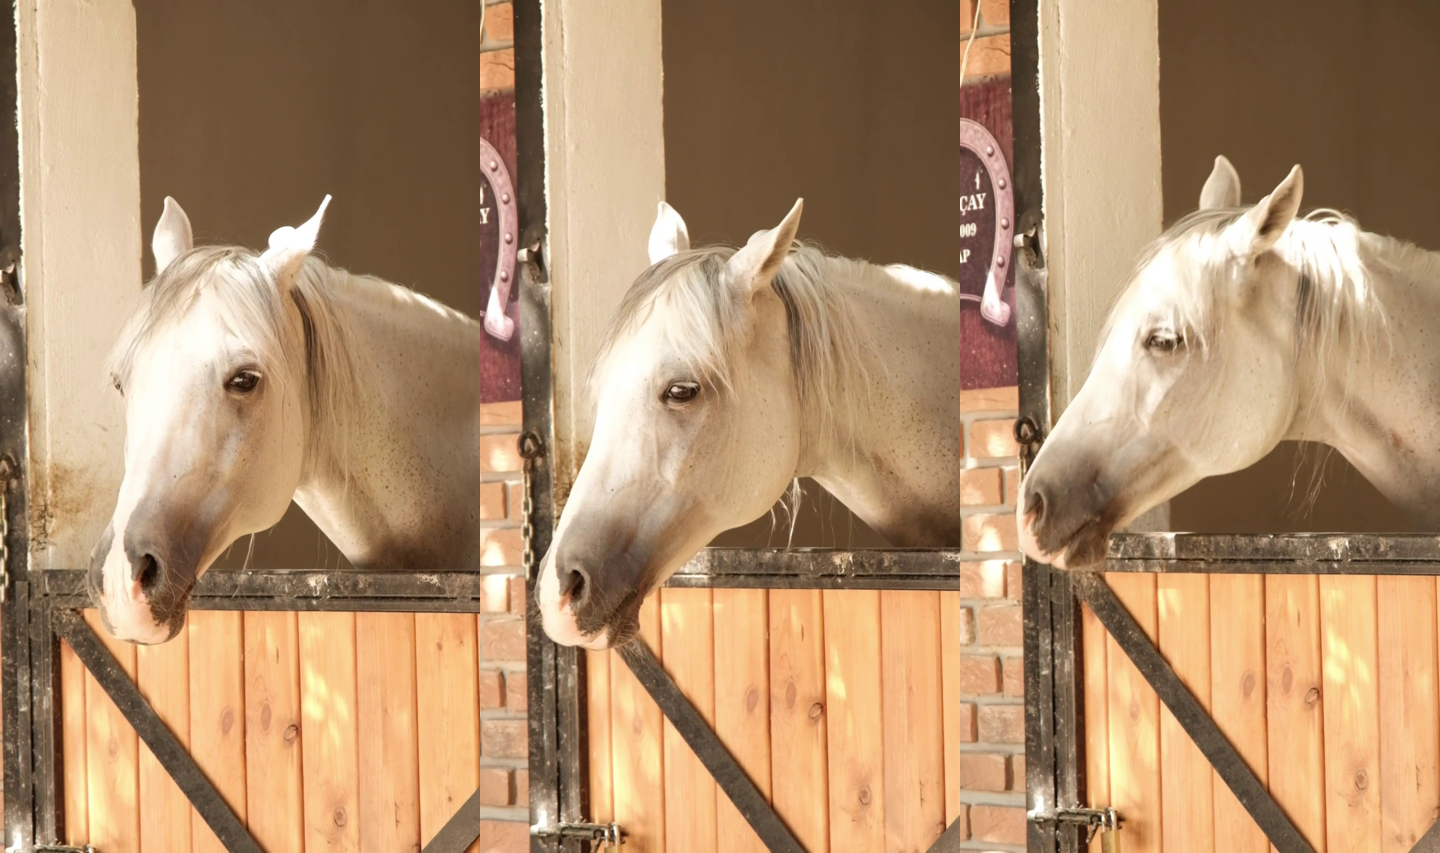

In [92]:
from PIL import Image as PILImage, ImageDraw

frames = [PILImage.open(path).convert("RGB") for path in frame_paths]

# Resize frames to a consistent width
target_width = 480
resized = []

for frame in frames:
    height = int(frame.height * target_width / frame.width)
    resized.append(frame.resize((target_width, height)))

# Arrange the frames horizontally
canvas = PILImage.new(
    "RGB",
    (sum(frame.width for frame in resized), max(frame.height for frame in resized)),
    "white"
)

x = 0
for frame in resized:
    canvas.paste(frame, (x, 0))
    x += frame.width

canvas.save("horse_contact_sheet.jpg")
display(canvas)

In [93]:
import os

print("Combined image exists:", os.path.exists("horse_contact_sheet.jpg"))

Combined image exists: True


### AI Video Frame Analysis Using Qwen

**Selected Model:** `qwen/qwen3-vl-8b-instruct`  
**Platform:** OpenRouter API  
**Model Type:** Vision-language model (VLM)

This cell sends three frames extracted from `horse.mp4` to the Qwen3-VL-8B-Instruct model through the OpenRouter API.

- **API key:** Retrieves the OpenRouter API key from environment variables.
- **Image encoding:** Converts each extracted frame into Base64 format.
- **Prompt preparation:** Instructs the model to describe the animal, its surroundings, and visible changes between frames.
- **API request:** Sends the prompt and images to the selected model.
- **Response handling:** Checks the HTTP status and extracts the model's text response.
- **Output display:** Displays the actual AI-generated description as formatted Markdown.

**Purpose:** Demonstrates how a vision-language model can analyze selected video frames and generate a natural-language description.

**Note:** The model analyzes three selected frames, not the entire video directly.

In [11]:
import os
import base64
import requests
from IPython.display import display, Markdown

# Use your existing OpenRouter API key variable if you already defined it.
api_key = os.environ.get("OPENROUTER_API_KEY")

if not api_key:
    print("OPENROUTER_API_KEY was not found in environment variables.")
else:
    image_paths = [
        "horse_frame_1.jpg",
        "horse_frame_2.jpg",
        "horse_frame_3.jpg"
    ]

    content = [{
        "type": "text",
        "text": (
            "Analyze these three video frames in order. "
            "Describe the animal, its surroundings, and the visible "
            "movement between frames. Reply in 3 short bullet points. "
            "Use only what is visible in the images."
        )
    }]

    for path in image_paths:
        with open(path, "rb") as image_file:
            image_data = base64.b64encode(
                image_file.read()
            ).decode("utf-8")

        content.append({
            "type": "image_url",
            "image_url": {
                "url": f"data:image/jpeg;base64,{image_data}"
            }
        })

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json"
        },
        json={
            "model": "qwen/qwen3-vl-8b-instruct",
            "messages": [{"role": "user", "content": content}],
            "max_tokens": 250,
            "temperature": 0.2
        },
        timeout=120
    )

    print("HTTP status:", response.status_code)

    if response.ok:
        result = response.json()
        message = result["choices"][0]["message"]
        answer = message.get("content")

        if answer:
            display(Markdown("## AI Video Frame Analysis\n" + answer))
            print("Finish reason:", result["choices"][0].get("finish_reason"))
        else:
            print("The model did not return a text answer.")
            print(result)
    else:
        print(response.text)

HTTP status: 200


## AI Video Frame Analysis
- A white horse with a speckled coat and dark eyes peers over a wooden and metal stable door.
- The horse is in a stable, with a brick wall and a decorative horseshoe sign visible to the left in later frames.
- The horse’s head moves slightly to the right and down between frames, and its mane appears to shift with the movement.

Finish reason: stop


In [13]:
print("AI response:")
print(answer)

AI response:
- A white horse with a speckled coat and dark eyes peers over a wooden and metal stable door.
- The horse is in a stable, with a brick wall and a decorative horseshoe sign visible to the left in later frames.
- The horse’s head moves slightly to the right and down between frames, and its mane appears to shift with the movement.
